# MIDTERM ESSAY
# Applied Probability and Statistics for Information Technology

**STUDENT'S NAME:** Huỳnh Trung Tín

**STUDENT ID:** 524K0033

**CLASS and GROUP:** 24K50201 and 01

Students submit this jupyter notebook presenting your solution and coding. Students giving correct solutions by using Markdown and typing your codes.

Save and submit only 1 file as: Student name_StudentID.ipynb (Example: TranVanAn_203456.ipynb)

You should solve and submit this report to your theory eLearning within 14 days, from the beginning of Nov 3rd 2025 to the end of Nov 16th 2025. Late submissions are not accepted. Submissions via email are not accepted.

This is an individual final report. NOT ALLOWED TO USE GOOGLE, CHATGPT, etc for copying similar solutions and codes. Any case of plagiarism will get 0.

# Question 1: (2 points)
A closed urn has 23 balls: 8 white, 6 blue and 9 red.

In [110]:
def cross(A, n):
    return {a+str(b+1) for a in A for b in range(n)}

urn = cross('W', 8) | cross('B', 6) | cross('R', 9)

Randomly select ***x*** balls
(know that each ball has the same probability of selection).

Use two last digits in your Student ID to get value x.

For example: Student ID: 0412347 => 47

In [111]:
def get_x(n):
    return int(( n / 99 ) * 4 + 6)

x = get_x(33)

Find a list of all possible ***x*** balls and assign to variable $U$.

In [112]:
import itertools as it
# your code

U = list(it.combinations(urn,x))

Let *X* represent the random variable corresponding to the number of red balls in ***x*** balls.

Let *Y* represent the random variable corresponding to the number of white balls in ***x*** balls.

Compute the probability:
$P(X=3|Y=1)$ (present the steps along with illustrative code).

In [113]:
# your code

#We find each combinations that has only 3 red
X_red=[u for u in U if sum('R' in ball for ball in u)==3]
#Then combinations that has only 1 white
Y_white=[u for u in U if sum('W' in ball for ball in u)==1]
#We find the intersection between X_red and Y_white
X_Y=list(set(X_red) & set(Y_white))
#To calculate conditional probability, we calculate P(X=3 || Y=1)/P(Y=1)
P=len(X_Y)/len(Y_white)
print(P)
print(f"Percentage wise : {P*100:.2f}%")

0.3356643356643357
Percentage wise : 33.57%


# Question 2: (2 points)

Study the statistical functions from the *scipy* library to solve the following questions.

**For each question, it is necessary to present the corresponding function, including its prototype, input, output, and the meaning of its parameters.** (1 point)

**2.1 (0.5 point):** Consider a random variable that follows normal distribution with mean 6 and variance 12.

Calculate: $P(4 \leq X \leq 8)$

**Write your answer here...**<br>
To calculate the probability $P(4 \le X \le 8)$, we use the Cumulative Distribution Function (CDF) from the scipy.stats library. The probability $P(a \le X \le b)$ is found by calculating $P(X \le b) - P(X \le a)$. The specific function used is `scipy.stats.norm.cdf()`.

This function has the meaning of calculating the Cumulative Distribution Function (CDF) for a given normal distribution. The CDF value at a point $x$ represents the probability that a random variable $X$ will take a value less than or equal to $x$ (i.e., $P(X \le x)$).

The prototype : `scipy.stats.norm.cdf(x, loc=0, scale=1)`

Parameters (Input):
- x: The quantile or "point" at which to evaluate the CDF. This is the value $x$ in $P(X \le x)$.
- loc: (location) The mean ($\mu$) of the normal distribution.
- scale: (scale) The **standard deviation** ($\sigma$) of the normal distribution.

Output: A float representing the probability $P(X \le x)$.

In [114]:
# your code
import scipy.stats as scp
import numpy as np
P8=scp.norm.cdf(x=8, loc=6, scale=np.sqrt(12))
P4=scp.norm.cdf(x=4, loc=6, scale=np.sqrt(12))
print("P(4<=X<=8)=",P8-P4)
print(f"Percentage wise :{(P8-P4)*100:2f}%")

P(4<=X<=8)= 0.4362971383492269
Percentage wise :43.629714%


**2.2 (0.5 point):** The number of bicycles crossing a bridge during the day follow a Poisson distribution with mean 28. What is the probability that on a randomly selected day 15 bicycles would have crossed the bridge?

$P(X=15)$

**Write your answer here...**

To calculate the probability $P(X=15)$ for a discrete distribution like Poisson, we use the **Probability Mass Function** (PMF).<br>
The PMF gives the probability of a random variable taking on a specific, exact integer value ($P(X=k)$). This is different from the CDF (Cumulative Distribution Function) used in the previous problem, which calculates the cumulative probability ($P(X \le k)$).The specific function used is `scipy.stats.poisson.pmf().`

We use this function to calculates the Probability Mass Function (PMF) for a given Poisson distribution.

The prototype : `scipy.stats.poisson.pmf(k, mu, loc=0)`

Parameters (Input):
- k: The specific non-negative integer (quantile) for which to calculate the probability. This is the $k$ in $P(X=k)$. In our case, k=15.
- mu: (mu, $\mu$) The mean of the Poisson distribution. This is often denoted as lambda ($\lambda$) and represents the average rate of events. In our case, mu=28.
- loc: (Optional) An offset parameter, which is almost always left at its default of 0 for standard Poisson calculations.

Output:A float representing the exact probability $P(X=k)$.

In [115]:
# your code
import scipy.stats as scp
P=scp.poisson.pmf(k=15, mu=28)
print("P(X=15)=",P)
print(f"Percentage Wise : {P*100:.2f}%")

P(X=15)= 0.0026954132921724844
Percentage Wise : 0.27%


**2.3 (0.5 point):** Suppose that service times at a call center are exponentially distributed with an average call lasting 8 minutes. If there are 3 call center agents serving calls, what is the probability that each person completes his or her work in 10 minutes? Assume that the duration of each call is independent of every other call.

$P(X \leq 10)$

**Write your answer here...**

This problem requires a two-step calculation:
- Find the probability that one agent finishes in $\le 10$ minutes using the exponential CDF.
- Since the agents' call times are independent, find the probability of all three succeeding by cubing the result from Step 1.
The function used for Step 1 is `scipy.stats.expon.cdf()`.

This function calculates the Cumulative Distribution Function (CDF) for the exponential distribution. It finds the probability that a random variable $X$ will take a value less than or equal to $x$ (i.e., $P(X \le x)$).

The prototype : `scipy.stats.expon.cdf(x, loc=0, scale=1)`

Parameters (Input):
- x: The quantile or "point" at which to evaluate the CDF. In this problem, x = 10 (minutes).
- loc: (Optional) The offset or shift parameter. This is typically left at 0 for standard exponential problems.
- scale: This is the key parameter. For scipy.stats.expon, the scale parameter is equal to the mean ($\mu$) of the distribution. In this problem, the average call time is 8 minutes, so scale = 8.

Output:A float representing the probability $P(X \le x)$.

In [116]:
# your code
import scipy.stats as scp
prob_one_agent = scp.expon.cdf(10, scale=8)
print(f"P(X<=10)={prob_one_agent}({prob_one_agent*100:.2f}%)")
prob_all_three = prob_one_agent ** 3
print(f"All 3 agents call finished <= 10 minutes :{prob_all_three}({prob_all_three*100:.2f}%)")

P(X<=10)=0.7134952031398099(71.35%)
All 3 agents call finished <= 10 minutes :0.3632228594351169(36.32%)


**2.4 (0.5 point):** From the experience, it is seen that 5% of the tyres produced by the machine are defective. Out of the 10 tyres produced, find the probability that at most 4 are defective.

$P(X≤4)$

**Write your answer here...**

This problem follows a **Binomial Distribution** since :
1. There is a fixed number of trials ($n=10$ tyres).
2. Each trial has two outcomes: "defective" (success) or "not defective" (failure).
3. The probability of success ($p=0.05$) is constant.
4. The trials are independent.

We need to find the probability of "at most 4" defects, which means $P(X≤4)$ = $P(X=0) + P(X=1) + P(X=2) + P(X=3) + P(X=4)$. This is a cumulative probability, so we use the Cumulative Distribution Function (CDF).The function used is `scipy.stats.binom.cdf()`.

This function calculates the Cumulative Distribution Function (CDF) for the binomial distribution. It sums the probabilities of getting $k$ successes or fewer (from 0 up to $k$).

The prototype : `scipy.stats.binom.cdf(k, n, p, loc=0)`

Parameters (Input):
- k: The number of successes (an integer). The function calculates $P(X \le k)$. In this case, k = 4.
- n: The total number of trials. In this case, n = 10.
- p: The probability of "success" (a tyre being defective) on a single trial. In this case, p = 0.05.

Output:A float representing the cumulative probability $P(X \le k)$.

In [117]:
# your code
import scipy.stats as scp 
P=scp.binom.cdf(k=4, n=10, p=0.05)
print("P(X<=4) =",P)
print(f"Percentage wise :{P*100:.2f}%")

P(X<=4) = 0.9999363101685547
Percentage wise :99.99%


# Question 3: Using Monte Carlo method to estimate π (2.0 points)

**Consider a circle C centered at (0,0) with a diameter of 1.** This question asks students to explore how the Monte Carlo method can be used to estimate the value of π through random number generation. **Students need to present a detailed solution, include an illustrations (by code or hand-drawn), and provide code that follows the presented solution**.

Now, imagine a square that circumscribes the circle. Randomly select points within the square, and use the Monte Carlo method to estimate the value of π based on the proportion of points that fall inside the circle. Write a simulator function of selecting point n times to estimate the π number. (1 point)

**Write your answer here...**

Monte Carlo methods are a broad class of computational algorithms that rely on repeated random sampling to obtain numerical results. One of the basic examples of getting started with the Monte Carlo algorithm is the estimation of Pi, the current problem we are solving

The core idea is to use probability. The logic is:
1) We randomly scatter a huge number of "darts" (points) uniformly across the square.
2) We count how many darts land inside the circle versus the total number of darts thrown.
3) The ratio of $\frac{\text{Points in Circle}}{\text{Total Points}}$ will be approximately equal to the ratio of $\frac{\text{Area of Circle}}{\text{Area of Square}}$.
4) Since we know the formulas for these areas, we can use this ratio to solve for $\pi$.

Using the parameters given to us in the problem, we can break down how the Monte Carlo method is performed in this scenario:

1. **Define the GeometryCircle (C):** 
   - Centered at $(0,0)$ with a diameter of 1. This means its radius ($r$) is 0.5
   - Square (S): The square circumscribes the circle. This means it is also centered at $(0,0)$ and its sides touch the circle's outermost points.. 
     * Since the radius is 0.5, the circle extends from -0.5 to +0.5 on both the x and y axes.
     * Therefore, the square's sides must be at $x = -0.5$, $x = 0.5$, $y = -0.5$, and $y = 0.5$.
     * The side length of the square is 1.
2. **Calculate the Areas**
   - Area of the Circle ($A_c$): $A_c = \pi \times r^2 = \pi \times (0.5)^2 = 0.25\pi$
   - Area of the Square ($A_s$): $A_s = \text{side}^2 = 1^2 = 1$ 
3. **Find the Probability Ratio**<br>
	The probability ($P$) that a random point landing anywhere inside the square will also fall inside the circle is the ratio of their areas:<br>
	$P(\text{in circle}) = \frac{\text{Area of Circle}}{\text{Area of Square}} = \frac{0.25\pi}{1} = 0.25\pi$ 
4. **The Simulation Logic**<br>
   We can estimate this probability by running a simulation:
   1. Generate $n$ total random points $(x, y)$ within the boundaries of the square. This means $x$ and $y$ will both be random numbers between -0.5 and 0.5.
   2. Count how many of those points ($points\_in\_circle$) fall **inside the circle**.
   3. A point $(x, y)$ is inside the circle if its distance from the center $(0,0)$ is less than or equal to the radius (0.5).
   4. Using the distance formula $d = \sqrt{x^2 + y^2}$, the condition is $\sqrt{x^2 + y^2} \le 0.5$.
   5. To avoid a slow square root calculation, we can square both sides: $x^2 + y^2 \le 0.5^2$ or $x^2 + y^2 \le 0.25$. This is our test.
5. **Estimating $\pi$** <br>
	The simulated ratio of points will approximate the actual area ratio: $\frac{points\_in\_circle}{n} \approx P(\text{in circle})$ <br>
	Now, we substitute the formula from Step 3: $\frac{points\_in\_circle}{n} \approx 0.25\pi$  <br>
	To solve for $\pi$, we just rearrange the equation: $\pi \approx \frac{\frac{points\_in\_circle}{n}}{0.25}$ $ \pi \approx 4 \times \frac{points\_in\_circle}{n}$

Total points simulated: 10000
Points inside circle: 7785
Estimated value of pi: 3.114
Percentage differnce between actual pi and estimated pi :0.8822%


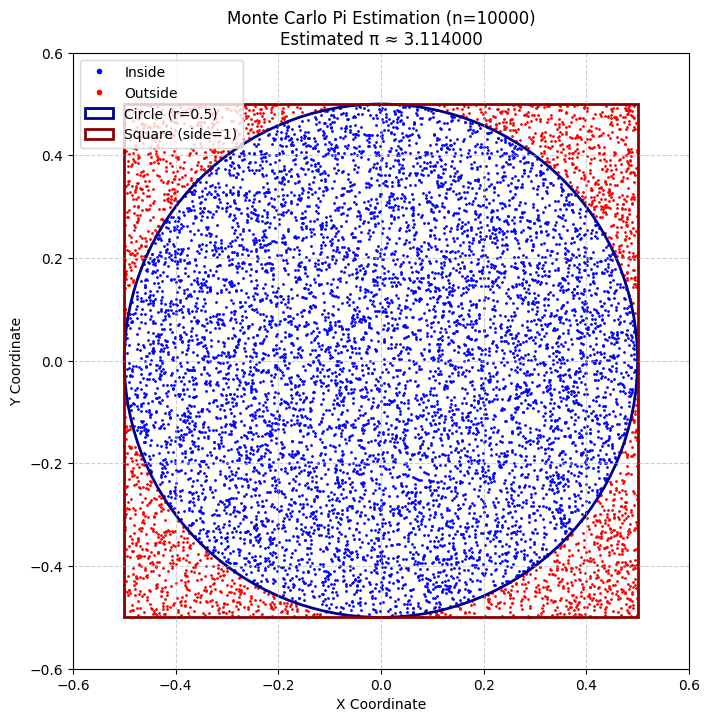

In [118]:
# your code
import random
import matplotlib.pyplot as plt
import math
 

def run_pi_simulation(n):
    points_in_circle = 0
    inside_points = []
    outside_points = []
    
    for _ in range(n):

        x = random.uniform(-0.5, 0.5)
        y = random.uniform(-0.5, 0.5)
        
        if x**2 + y**2 <= 0.25:
            points_in_circle += 1
            inside_points.append((x, y))
        else:
            outside_points.append((x, y))
            
    pi_estimate = 4 * (points_in_circle / n) if n > 0 else 0
    
    return pi_estimate, inside_points, outside_points

def plot_simulation(inside_points, outside_points, pi_estimate, n):

    
    fig,ax = plt.subplots(figsize=(8, 8))
    #Can't remove the fig despite not being used due to needing to set up the ax properly

    if inside_points:
        inside_x, inside_y = zip(*inside_points)
        ax.scatter(inside_x, inside_y, color='blue', s=1, label='Inside Circle')
    
    if outside_points:
        outside_x, outside_y = zip(*outside_points)
        ax.scatter(outside_x, outside_y, color='red', s=1, label='Outside Circle')
    

    circle = plt.Circle((0, 0), 0.5, color='darkblue', fill=False, linewidth=2, label='Circle (r=0.5)')
    ax.add_patch(circle)
    

    square = plt.Rectangle((-0.5, -0.5), 1, 1, color='darkred', fill=False, linewidth=2, label='Square (side=1)')
    ax.add_patch(square)
    

    ax.set_aspect('equal', adjustable='box')
    ax.set_xlim(-0.6, 0.6)
    ax.set_ylim(-0.6, 0.6)
    ax.set_xlabel('X Coordinate')
    ax.set_ylabel('Y Coordinate')
    
    title = f"Monte Carlo Pi Estimation (n={n})\nEstimated π ≈ {pi_estimate:.6f}"
    ax.set_title(title)
    
    handles = []
    if inside_points:
        handles.append(plt.Line2D([0], [0], marker='o', color='w', label='Inside',
                                  markerfacecolor='blue', markersize=5))
    if outside_points:
        handles.append(plt.Line2D([0], [0], marker='o', color='w', label='Outside',
                                  markerfacecolor='red', markersize=5))
    handles.extend([circle, square])
    
    ax.legend(handles=handles)
    ax.grid(True, linestyle='--', alpha=0.6)
    
    plt.show()



n_str = input("\nEnter the number of points to simulate(must be a positive integer larger than 0): ")
# n_points = int(100000)
n_points = int(n_str)

pi_est, inside, outside = run_pi_simulation(n_points)
pi=math.pi
pi_diff=abs(pi-pi_est)/((pi+pi_est)/2)*100

print(f"Total points simulated: {n_points}")
print(f"Points inside circle: {len(inside)}")
print(f"Estimated value of pi: {pi_est}")
print(f"Percentage differnce between actual pi and estimated pi :{pi_diff:.4f}%")

plot_simulation(inside, outside, pi_est, n_points)


# Question 4: Estimating the population variance from sample variance (2.0 points)

Let $\{X_1, X_2, \ldots, X_{50}\}$ be a random sample from the population with an unknown probability density function f(x,θ), where θ∈Θ. We have **equation (1): $E[S^2]=\sigma^2$**.

```
Need to use your STUDENT ID to get the value for the code below. READ COMMENT IN CODE.
```

In [119]:
import numpy as np
import random

# Example: your Student ID 524K0033 => get code: 0033
a = 0 # two first digits in our code   => 00
b = 33 # two last digits in our code   => 33
population_data = list(np.random.normal(a, b, 10000))

Let the population consist of 10000 elements, as described above. Students should **present in detail the method for estimating the population variance based on a sample** (according to quation [1]). Provide a thorough explanation, including the mathematical formulas and illustrative code.

**Write your answer here...**

In order to estimate ($\sigma^2$) using a sample ($X_1, \dots, X_{50}$), we will focuses on the key of the problem, being Equation (1): $E[S^2] = \sigma^2$, which states that our estimator, $S^2$ (which we'll call sample variance $s^2$), must be unbiased. This means its expected value (the average of all possible sample variances) must be equal to the true population variance.

1. **Theoretical Explanation**
   * Population Variance ($\sigma^2$): This is the value we want to find. It measures the average squared deviation of all elements in the population from the population mean ($\mu$).
   * Sample Variance ($s^2$): This is our estimator. It is calculated using only the data from our sample (of size $n=50$). A naive approach would be to find the average squared deviation of the sample data from the sample mean ($\bar{x}$).
   * The Problem with $\bar{x}$: We don't know the true population mean $\mu$, so we must use the sample mean $\bar{x}$ as an estimate. However, the sample mean $\bar{x}$ is, by definition, the value that minimizes the sum of squared differences for that specific sample. This means the deviations within the sample, $(x_i - \bar{x})$, will, on average, be smaller than the true deviations from the population mean, $(x_i - \mu)$.
   * Bessel's Correction (The $n-1$ Divisor):
     * If we simply averaged the squared differences using $n$ (i.e., $\frac{1}{n}\sum(x_i - \bar{x})^2$), our estimate would be biased. It would consistently underestimate the true population variance.
     * To correct for this bias, we divide by $n-1$ instead of $n$. This is known as Bessel's Correction.
     * This correction "inflates" the estimate just enough to account for the fact that we're using $\bar{x}$ instead of $\mu$.
     * The resulting estimator, $s^2 = \frac{1}{n-1}\sum(x_i - \bar{x})^2$, is an unbiased estimator of $\sigma^2$. This is precisely what Equation (1) describes: $E[s^2] = \sigma^2$.
2. **Mathematical Formulas**
	1. Population Variance ($\sigma^2$): (Where $N$ is population size and $\mu$ is population mean)
	$$\sigma^2 = \frac{1}{N} \sum_{i=1}^{N} (x_i - \mu)^2$$
	2. Sample Mean ($\bar{x}$): (Where $n$ is sample size)
	$$\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i$$
	3. Sample Variance ($s^2$) (Unbiased Estimator):This is the formula that satisfies Equation (1).
	$$s^2 = \frac{1}{n-1} \sum_{i=1}^{n} (x_i - \bar{x})^2$$


In [120]:
# your code
n=50 #sample size
actual_population_variance = np.var(population_data)
true_population_variance = b**2
print(f"Actual Variance of Generated Population: {actual_population_variance:.4f}")

sample_data = np.random.choice(population_data, n, replace=False)
sample_variance_s2 = np.var(sample_data, ddof=1)
print(f"Sample Estimate (s^2) using (n-1): {sample_variance_s2:.4f}")

num_simulations = 20000
biased_estimates = []
unbiased_estimates = []

for _ in range(num_simulations):
   
    sample = np.random.choice(population_data, n, replace=False)
    
    biased_var = np.var(sample, ddof=0)
    biased_estimates.append(biased_var)
    
    unbiased_var = np.var(sample, ddof=1)
    unbiased_estimates.append(unbiased_var)

avg_biased_estimate = np.mean(biased_estimates)
avg_unbiased_estimate = np.mean(unbiased_estimates)

print(f"True Theoretical Population Variance: {true_population_variance}")
print(f"Average of Biased Estimates (dividing by n=50): {avg_biased_estimate:.4f}")
print(f"Average of Unbiased Estimates (dividing by n-1=49): {avg_unbiased_estimate:.4f}")

Actual Variance of Generated Population: 1079.4660
Sample Estimate (s^2) using (n-1): 1388.8882
True Theoretical Population Variance: 1089
Average of Biased Estimates (dividing by n=50): 1058.7462
Average of Unbiased Estimates (dividing by n-1=49): 1080.3533


# Question 5: (2.0 points) Relationship between Poisson Distribution and Binomial Distribution

a) Study the theory of Poisson distribution and Binomial distribution.

b) Explain the relationship between the two distributions.

c) Implement a simulation with 1000 samples, illustrating the similarity between the two distributions with appropriate parameters.

d) Plot the distributions and comment on the results.

**Write your answer here...**

**Binomial Distribution** <br>
The Binomial distribution, denoted as $B(n, p)$, models the number of successes ($k$) in a fixed number of independent trials ($n$).

- Parameters :
  *  $n$: The total number of trials.
  *  $p$: The probability of success on a single trial.
- Conditions :
  1) There is a fixed number of trials ($n$).
  2) Each trial is independent of the others.
  3) Each trial has only two possible outcomes (e.g., "success" or "failure").
  4) The probability of success ($p$) remains constant for all trials.
- Mean : $\mu = np$
- Variance : $\sigma^2 = np(1-p)$

**Poisson Distribution** <br>
The Poisson distribution, denoted as $P(\lambda)$, models the number of events ($k$) occurring within a fixed interval of time or space.

- Parameter :
  * $\lambda$ (lambda): The average rate (or mean number) of events in that interval.
- Conditions:
  1) Events occur independently.
  2) The average rate ($\lambda$) at which events occur is constant.
  3) Two events cannot occur at the exact same instant.
- Mean and Variance : $\mu = \sigma^2 = \lambda$

**Relationship** <br>
The Poisson distribution is the limiting case of the Binomial distribution.

A Binomial distribution $B(n, p)$ can be closely approximated by a Poisson distribution $P(\lambda)$ when
1. $n$ (number of trials) is very large.
2. $p$ (probability of success) is very small.
3. The mean $\lambda = np$ is a moderate, finite value.

This approximation is often used for modeling "rare events." For example, the number of typos in a large book can be modeled as a Binomial problem ( $n$ = number of words, $p$ = tiny probability of a typo) or, much more simply, as a Poisson problem ($\lambda$ = average typos per book).


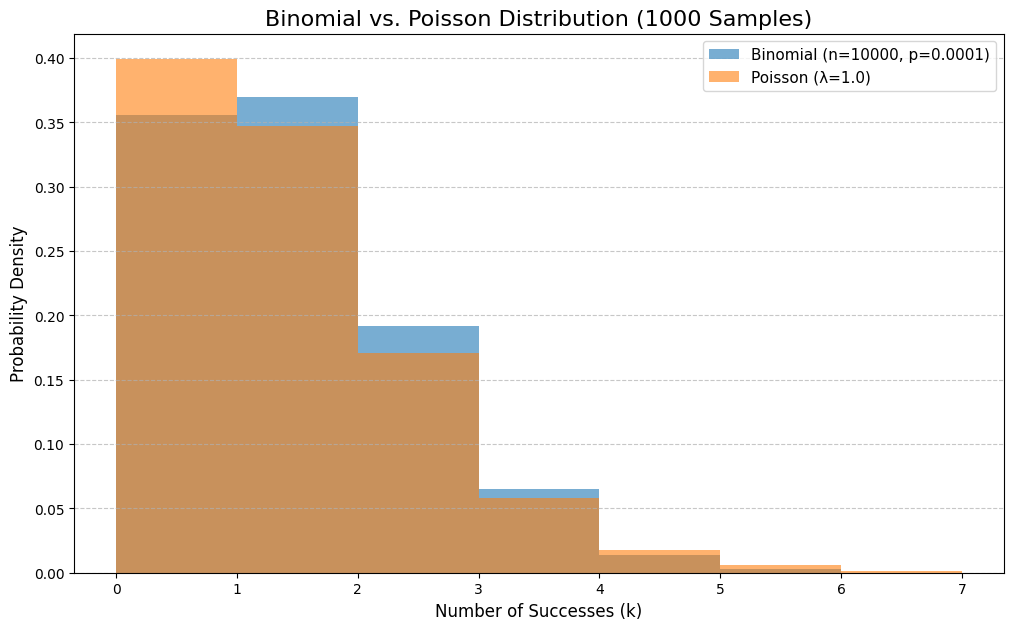


Observation: The plot shows that the two histograms are nearly identical, overlapping significantly. This visually confirms the theory: when 'n' is large and 'p' is small, the Binomial distribution is extremely well-approximated by the Poisson distribution with lambda = n*p.


In [121]:
# Your code
import numpy as np
import matplotlib.pyplot as plt
import random

random=10**random.randint(2,8) #For diversity
n = 1*random  # num of trials 
p = 1/random  # prob
lam = n * p  # lambda = n*p is moderate(should be moderate, i think)
num_samples = 1000  

binomial_samples = np.random.binomial(n, p, num_samples)
poisson_samples = np.random.poisson(lam, num_samples)

max_val = max(binomial_samples.max(), poisson_samples.max())
min_val = min(binomial_samples.min(), poisson_samples.min())
bins = np.arange(min_val, max_val + 2) #Should update the size of the graph based on the size of the samples(god i hope it works)

#Use histograms to show the overlays between distributions, 
plt.figure(figsize=(12, 7))
plt.hist(binomial_samples, bins=bins, density=True, alpha=0.6, label=f'Binomial (n={n}, p={p})')
plt.hist(poisson_samples, bins=bins, density=True, alpha=0.6, label=f'Poisson (λ={lam})')

plt.title(f'Binomial vs. Poisson Distribution (1000 Samples)', fontsize=16)
plt.xlabel('Number of Successes (k)', fontsize=12)
plt.ylabel('Probability Density', fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)


plt.show()

# To cross references the results
# print(f"Parameters used: n={n}, p={p}, lambda={lam}")
# print(f"Binomial Mean (Sample): {np.mean(binomial_samples):.4f} (Theoretical: {n*p})")
# print(f"Poisson Mean (Sample): {np.mean(poisson_samples):.4f} (Theoretical: {lam})")
# print(f"Binomial Var (Sample): {np.var(binomial_samples):.4f} (Theoretical: {n*p*(1-p):.2f})")
# print(f"Poisson Var (Sample): {np.var(poisson_samples):.4f} (Theoretical: {lam})")

#The actual comment
print("\nObservation: The plot shows that the two histograms are nearly identical, overlapping significantly. This visually confirms the theory: when 'n' is large and 'p' is small, the Binomial distribution is extremely well-approximated by the Poisson distribution with lambda = n*p.")

# **This is the end of the essay!**